# Homework 2 — Regresión lineal

Solución de `homework.md` usando `data/car_fuel_efficiency_2026.csv`.

In [1]:
import pandas as pd

In [2]:
df = pd.read_csv("data/car_fuel_efficiency_2026.csv")

In [3]:
df.shape

(10000, 11)

In [4]:
df.columns = df.columns.str.lower().str.replace(" ", "_")

In [5]:
df.columns

Index(['model_year', 'origin', 'fuel_type', 'drivetrain', 'num_doors',
       'engine_displacement', 'num_cylinders', 'horsepower', 'vehicle_weight',
       'acceleration', 'fuel_efficiency_mpg'],
      dtype='str')

In [6]:
using_cols = ["engine_displacement", "horsepower", "vehicle_weight", "model_year", "fuel_efficiency_mpg"]

In [7]:
base = ["engine_displacement", "horsepower", "vehicle_weight", "model_year"]

In [8]:
df = df[using_cols]

## Q1. Missing values

In [9]:
df.isnull().sum()

engine_displacement      0
horsepower             877
vehicle_weight           0
model_year               0
fuel_efficiency_mpg      0
dtype: int64

**Respuesta:** `horsepower`

## EDA — ¿cola larga en `fuel_efficiency_mpg`?

In [10]:
import seaborn as sns

<Axes: xlabel='fuel_efficiency_mpg', ylabel='Count'>

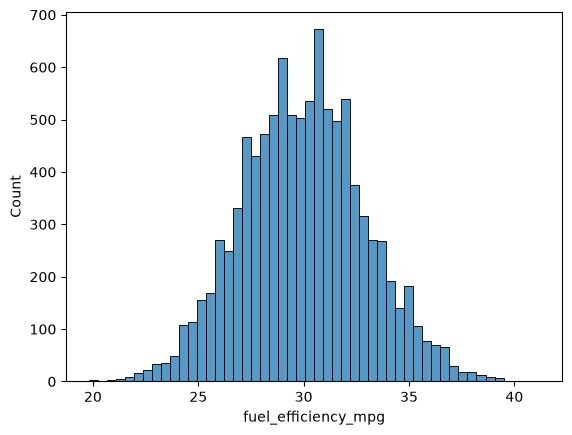

In [11]:
sns.histplot(df["fuel_efficiency_mpg"], bins=50)

In [12]:
for col in df[using_cols].columns:
    print(col)
    print(df[col].unique()[:5])
    print(df[col].nunique())
    print()

engine_displacement
[2180 2390 2320 2130 2580]
127

horsepower
[243. 272. 267. 258. 304.]
153

vehicle_weight
[3870 4210 4240 4490 4510]
176

model_year
[2006 2008 1996 1989 1994]
50

fuel_efficiency_mpg
[31.9 31.3 27.5 28.5 31. ]
188



**Respuesta:** No tiene cola larga: la distribución es casi simétrica (skew ≈ 0.08, media y mediana prácticamente iguales: 29.998 vs 30.0).

## Q2. Median value of horsepower

In [13]:
df["horsepower"].median()

np.float64(254.0)

**Respuesta:** 254.0

In [14]:
import numpy as np

In [15]:
n = len(df)
n_val = int(n * 0.2)
n_test = int(n * 0.2)
n_train = n - n_val - n_test

np.random.seed(42)
idx = np.arange(n)
np.random.shuffle(idx)

df_train = df.iloc[idx[:n_train]]
df_val = df.iloc[idx[n_train : n_train + n_val]]
df_test = df.iloc[idx[n_train + n_val:]]

df_train = df_train.reset_index(drop=True)
df_val = df_val.reset_index(drop=True)
df_test = df_test.reset_index(drop=True)

y_train = df_train["fuel_efficiency_mpg"].values
y_val = df_val["fuel_efficiency_mpg"].values
y_test = df_test["fuel_efficiency_mpg"].values

del df_train["fuel_efficiency_mpg"]
del df_val["fuel_efficiency_mpg"]
del df_test["fuel_efficiency_mpg"]

In [16]:
df_train

,engine_displacement,horsepower,vehicle_weight,model_year
0,1900,239.0,3790,2015
1,2000,224.0,4380,1992
2,2330,286.0,4090,2022
3,2300,NaN,4150,1997
4,2340,269.0,4400,2001
...,...,...,...,...
5995,2280,242.0,4590,2018
5996,2300,NaN,4240,1984
5997,2240,255.0,4190,1989
5998,2430,254.0,4280,2020


In [17]:
for a in [ df_train, df_val, df_test]:
    print(len(a))

6000
2000
2000


In [18]:
y_train

array([32.5, 29.1, 34.1, ..., 27.7, 31.6, 28. ], shape=(6000,))

## Q3. Missing value imputation (0 vs mean)

In [19]:
df_train.info()

<class 'pandas.DataFrame'>
RangeIndex: 6000 entries, 0 to 5999
Data columns (total 4 columns):
 #   Column               Non-Null Count  Dtype  
---  ------               --------------  -----  
 0   engine_displacement  6000 non-null   int64  
 1   horsepower           5462 non-null   float64
 2   vehicle_weight       6000 non-null   int64  
 3   model_year           6000 non-null   int64  
dtypes: float64(1), int64(3)
memory usage: 187.6 KB


In [20]:
media_train = df_train.mean()

In [21]:
def prepare_X(df, value_fill=0):
    df_copy = df.copy()
    return df_copy[base].fillna(value_fill)

In [22]:
def train_linear_regression(X, y):
    ones = np.ones(X.shape[0])
    X = np.column_stack([ones, X])

    XTX = X.T.dot(X)
    XTX_inv = np.linalg.inv(XTX)
    w_full = XTX_inv.dot(X.T).dot(y)

    return w_full[0], w_full[1:]

In [23]:
X_train = prepare_X(df_train, media_train)
w0, w = train_linear_regression(X_train, y_train)

In [24]:
def rmse(y, y_pred):
    se = (y - y_pred) ** 2
    mse = se.mean()
    return np.sqrt(mse)

In [25]:
X_val = prepare_X(df_val, media_train)
y_pred = w0 + X_val.dot(w)

In [26]:
y_pred

0       31.542884
1       29.925051
2       31.564595
3       29.954618
4       31.001714
          ...    
1995    33.091012
1996    27.179325
1997    30.544083
1998    30.857012
1999    31.553137
Length: 2000, dtype: float64

<Axes: ylabel='Count'>

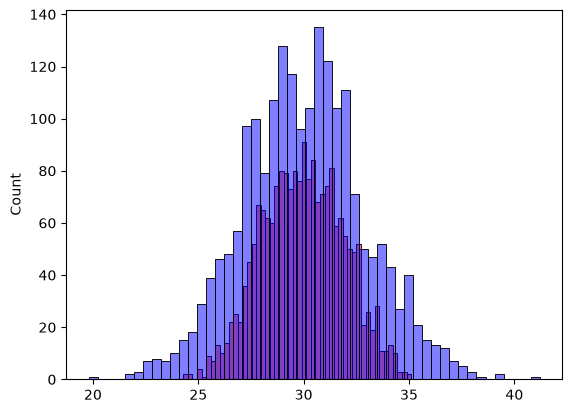

In [27]:
sns.histplot(y_pred, color="red", alpha=0.5, bins=50)
sns.histplot(y_val, color="blue", alpha=0.5, bins=50)

In [28]:
rmse_mean = round(rmse(y_val, y_pred), 3)
rmse_mean

np.float64(2.202)

---

In [29]:
X_train_0  = prepare_X(df_train)
w0_0, w_0 = train_linear_regression(X_train_0, y_train)

In [30]:
X_val_0 = prepare_X(df_val)

In [31]:
y_pred_0 = w0_0 + X_val_0.dot(w_0)

In [32]:
y_pred_0

0       31.645021
1       29.865730
2       31.588389
3       30.025841
4       31.006497
          ...    
1995    33.080327
1996    27.051882
1997    30.531333
1998    30.750851
1999    31.629128
Length: 2000, dtype: float64

<Axes: ylabel='Count'>

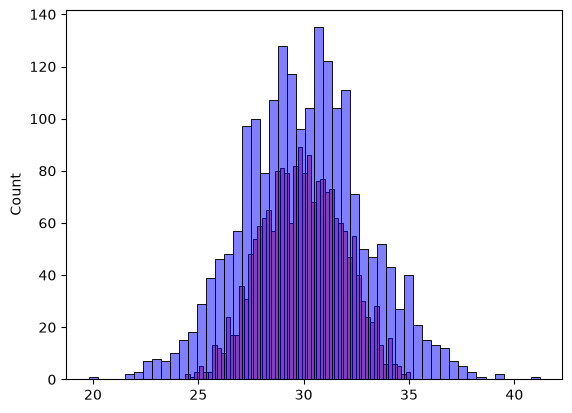

In [33]:
sns.histplot(y_pred_0, color="red", alpha=0.5, bins=50)
sns.histplot(y_val, color="blue", alpha=0.5, bins=50)

In [34]:
rmse_0 = round(rmse(y_val, y_pred_0), 3)
rmse_0

np.float64(2.205)

**Respuesta:** With mean: menor RMSE en validación (2.202 vs 2.205).

## Q4. Regularized linear regression

In [35]:
def train_linear_regression_reg(X, y, r=0.001):
    ones = np.ones(X.shape[0])
    X = np.column_stack([ones, X])

    XTX = X.T.dot(X)
    XTX = XTX + r * np.eye(XTX.shape[0])

    XTX_inv = np.linalg.inv(XTX)
    w_full = XTX_inv.dot(X.T).dot(y)

    return w_full[0], w_full[1:]

In [36]:
for r in [0, 0.01, 0.1, 1, 5, 10, 100]:
    X_train_r = prepare_X(df_train)
    w0_r, w_r = train_linear_regression_reg(X_train_r, y_train, r=r)

    X_val_r = prepare_X(df_val)
    y_pred_r = w0_r + X_val_r.dot(w_r)
    score = rmse(y_val, y_pred_r)

    print(r, w0_r, round(score, 4))

0 -153.8849618823138 2.2053
0.01 -148.3092124404723 2.2058
0.1 -111.83871039306318 2.2241
1 -32.331865964971264 2.3492
5 -7.7728522099734025 2.4094
10 -3.9871164160193766 2.4195
100 -0.40821964884790385 2.4292


**Respuesta:** r = 0 (RMSE = 2.2053, el más bajo)

## Q5. Effect of the seed on the RMSE

In [37]:
std_list = []

for k in [0, 1, 2, 3, 4, 5, 6, 7, 8, 9]:
    np.random.seed(k)
    idx = np.arange(n)
    np.random.shuffle(idx)

    df_train = df.iloc[idx[:n_train]]
    df_val = df.iloc[idx[n_train : n_train + n_val]]
    df_test = df.iloc[idx[n_train + n_val :]]

    df_train = df_train.reset_index(drop=True)
    df_val = df_val.reset_index(drop=True)
    df_test = df_test.reset_index(drop=True)

    y_train = df_train["fuel_efficiency_mpg"].values
    y_val = df_val["fuel_efficiency_mpg"].values
    y_test = df_test["fuel_efficiency_mpg"].values

    del df_train["fuel_efficiency_mpg"]
    del df_val["fuel_efficiency_mpg"]
    del df_test["fuel_efficiency_mpg"]

    X_train = prepare_X(df_train)
    w0, w = train_linear_regression(X_train, y_train)
    
    X_val = prepare_X(df_val)
    y_pred = w0 + X_val.dot(w)
    score = rmse(y_val, y_pred)
    std_list.append(score)
    
    print(k, w0, round(score, 3))

0 -150.42885945053604 2.239
1 -151.61231559524532 2.202
2 -152.84068112584038 2.163
3 -152.33298096679098 2.204
4 -158.8885681645812 2.202
5 -151.8573533886124 2.246
6 -154.3717913727048 2.27
7 -155.01835258995723 2.191
8 -150.4381740048234 2.217
9 -154.3600748895819 2.207


In [38]:
round(np.std(std_list), 3)

np.float64(0.029)

**Respuesta:** std ≈ 0.029

## Q6. Final model (train+val, r=0.001) evaluated on test

In [39]:
np.random.seed(9)
idx = np.arange(n)
np.random.shuffle(idx)

df_train = df.iloc[idx[:n_train]].reset_index(drop=True)
df_val = df.iloc[idx[n_train : n_train + n_val]].reset_index(drop=True)
df_test = df.iloc[idx[n_train + n_val :]].reset_index(drop=True)

y_train = df_train["fuel_efficiency_mpg"].values
y_val = df_val["fuel_efficiency_mpg"].values
y_test = df_test["fuel_efficiency_mpg"].values

del df_train["fuel_efficiency_mpg"]
del df_val["fuel_efficiency_mpg"]
del df_test["fuel_efficiency_mpg"]

In [40]:
df_full_train = pd.concat([df_train, df_val])
df_full_train = df_full_train.reset_index(drop=True)

In [41]:
X_full_train = prepare_X(df_full_train)

In [42]:
y_full_train = np.concatenate([y_train, y_val])

In [43]:
w0, w = train_linear_regression_reg(X_full_train, y_full_train, r=0.001)

In [44]:
X_test = prepare_X(df_test)
y_pred = w0 + X_test.dot(w)
score = rmse(y_test, y_pred)
round(score, 3)

np.float64(2.236)

**Respuesta:** RMSE ≈ 2.236